# Notebook 04: Scenario 1 - Real Dataset Analysis
**Project:** Real vs. Synthetic Data: Comparative Analysis and Visualization
**Data analysed:** the cleaned real data (`data/cleaned/online_shoppers_cleaned.csv`, 12,199 sessions)

This is the reference analysis. The analysis covers univariate, bivariate and multivariate views and a monthly trend, and ends with five key findings. Each figure is followed by a short interpretation.

**Fair-comparison settings.** The x-axis limit of a numerical column is the *real* 99th percentile in all scenarios; the y-axis limits are the larger of the real and synthetic values, so neither scenario is clipped. Counts and shares are shown as a percentage of each dataset's rows.

**Where the work is done.** Charts that Power BI can draw natively (histograms, bars, scatter, line, donut) are repeated in Power BI in a later phase. Charts it cannot draw (KDE, pair plot, heatmaps) are produced here.

## 1. Setup

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import scenario_lib as L
L.use_style()

real = pd.read_csv(ROOT / "data" / "cleaned" / "online_shoppers_cleaned.csv")
syn = pd.read_csv(ROOT / "data" / "synthetic" / "synthetic_online_shoppers.csv")
S = L.make_settings(real, syn)                 # identical for every scenario
LIM = L.trend_limits(real, syn)
df = real
COLOR = L.SCENARIO_COLOR["Real"]
FIG = ROOT / "figures" / "real/scenario1"
RES = ROOT / "results" / "scenarios" / "scenario1_real"
RES.mkdir(parents=True, exist_ok=True)
r2 = lambda d: {k: round(float(v), 4) for k, v in d.items()}
json.dump({"x_axis_limit (real p99)": r2(S["hi"]), "histogram_y_max (% of rows)": r2(S["hist_ymax"]), "kde_y_max": r2(S["kde_ymax"]),
           "category_y_max (% of rows)": r2(S["cat_ymax"]), "purchase_rate_axis_max": S["rate_ymax"], "grouped_bar_axis_max": S["bar_ymax"],
           "bubble_x_max": S["bubble_xmax"], "random_seed_for_samples": L.SEED}, open(ROOT / "results" / "scenarios" / "plot_settings.json", "w"), indent=1)
print("Scenario 1 data:", df.shape, "| numerical:", len(L.NUM), "| categorical:", len(L.CAT))
print("Missing values:", int(df.isna().sum().sum()), "| Revenue:", df.Revenue.value_counts().to_dict())

Scenario 1 data: (12199, 24) | numerical: 14 | categorical: 10
Missing values: 0 | Revenue: {'No_Purchase': 10291, 'Purchase': 1908}


## 2. Univariate analysis

### 2.1 Numerical columns: mean, median, mode, standard deviation, quartiles, skewness and outliers
Outliers are counted with the 1.5 x IQR rule on this scenario's own data. `above axis limit` is the share of values beyond the real 99th percentile used as the plot limit.

In [2]:
num_stats = L.univariate_numeric(df, S)
num_stats.to_csv(RES / "univariate_numeric.csv")
num_stats.round(3)

,mean,median,mode,std,min,Q1,Q3,max,skewness,IQR outliers (n),IQR outliers (%),zeros (%),above axis limit (%)
column,,,,,,,,,,,,,
Administrative,2.340,1.000,0.0,3.331,0.0,0.000,4.000,27.000,1.946,404,3.312,46.209,0.926
Administrative_Duration,79.493,9.000,0.0,157.518,0.0,0.000,94.750,1178.967,3.816,1147,9.402,47.315,1.000
Informational,0.509,0.000,0.0,1.276,0.0,0.000,0.000,24.000,4.013,2631,21.567,78.433,0.680
Informational_Duration,32.767,0.000,0.0,120.155,0.0,0.000,0.000,1005.421,5.540,2405,19.715,80.285,1.000
ProductRelated,31.572,18.000,1.0,40.690,0.0,8.000,38.000,282.000,3.056,1007,8.255,0.262,1.000
ProductRelated_Duration,1183.082,609.542,0.0,1652.525,0.0,193.708,1477.565,11246.177,3.022,951,7.796,5.115,1.000
BounceRates,0.020,0.003,0.0,0.045,0.0,0.000,0.017,0.200,3.173,1422,11.657,45.233,0.000
ExitRates,0.041,0.025,0.2,0.046,0.0,0.014,0.048,0.200,2.239,1319,10.812,0.623,0.000
PageValues,5.953,0.000,0.0,18.658,0.0,0.000,0.000,361.764,6.349,2730,22.379,77.621,1.000


**Interpretation.** Every numerical column is right-skewed except Product_Page_Share (skewness -2.36, because most sessions are almost entirely product pages). The mean is far above the median for the count and duration columns (for example ProductRelated mean 31.6, median 18; Total_Duration mean 1,295 s, median 691 s), so the median describes a typical session better than the mean. Zeros are common: 78% of sessions have PageValues of 0, 80% have no informational time, 46% to 47% have no administrative page, and 45% have a bounce rate of 0. For continuous columns with many ties the mode is simply 0 (or 1 for page counts); the mode of ExitRates is 0.2, the capped maximum. Avg_Time_Per_Page has a skewness of 10.3, driven by a few sessions that spend very long on a single page. The IQR rule flags 22% of PageValues and Informational values as outliers, but this is because the third quartile is 0, so every non-zero value is flagged; these are valid sessions, not errors. For the duration and count columns, 3% to 9% of sessions are flagged, which reflects the long tail.

### 2.2 Categorical columns: frequency and percentage

In [3]:
cat_freq = L.categorical_freq(df)
cat_freq.to_csv(RES / "categorical_frequency.csv", index=False)
top = cat_freq.sort_values(["column", "count"], ascending=[True, False]).groupby("column").head(3)
top.round(2).reset_index(drop=True)      # the three most frequent levels of each column (the full table is in the CSV)

,column,level,count,percent
0,Browser,Browser_2,7880,64.60
1,Browser,Browser_1,2424,19.87
2,Browser,Browser_4,731,5.99
3,Month,May,3327,27.27
4,Month,Nov,2979,24.42
5,Month,Mar,1860,15.25
6,OperatingSystems,OS_2,6539,53.60
7,OperatingSystems,OS_1,2546,20.87
8,OperatingSystems,OS_3,2529,20.73
9,Quarter,Q4,5234,42.91


**Interpretation.** Traffic is concentrated: May (27.3%) and November (24.4%) together account for 52% of sessions, and with March and December for 81%; Q4 alone holds 42.9%. Returning visitors make up 85.5% of sessions, new visitors 13.9% and 'Other' 0.7%. Most sessions are on weekdays (76.6%). Session_Length_Band is split almost in thirds (34.0%, 33.2%, 32.8%) because it was defined from tertiles. The coded columns are dominated by one or two levels: OS_2 (53.6%), Browser_2 (64.6%), Region_1 (38.6%) and Traffic_2 (32.1%). Purchases are a minority class: 15.64% (1,908 of 12,199 sessions), about one session in 6.4.

### 2.3 Histograms

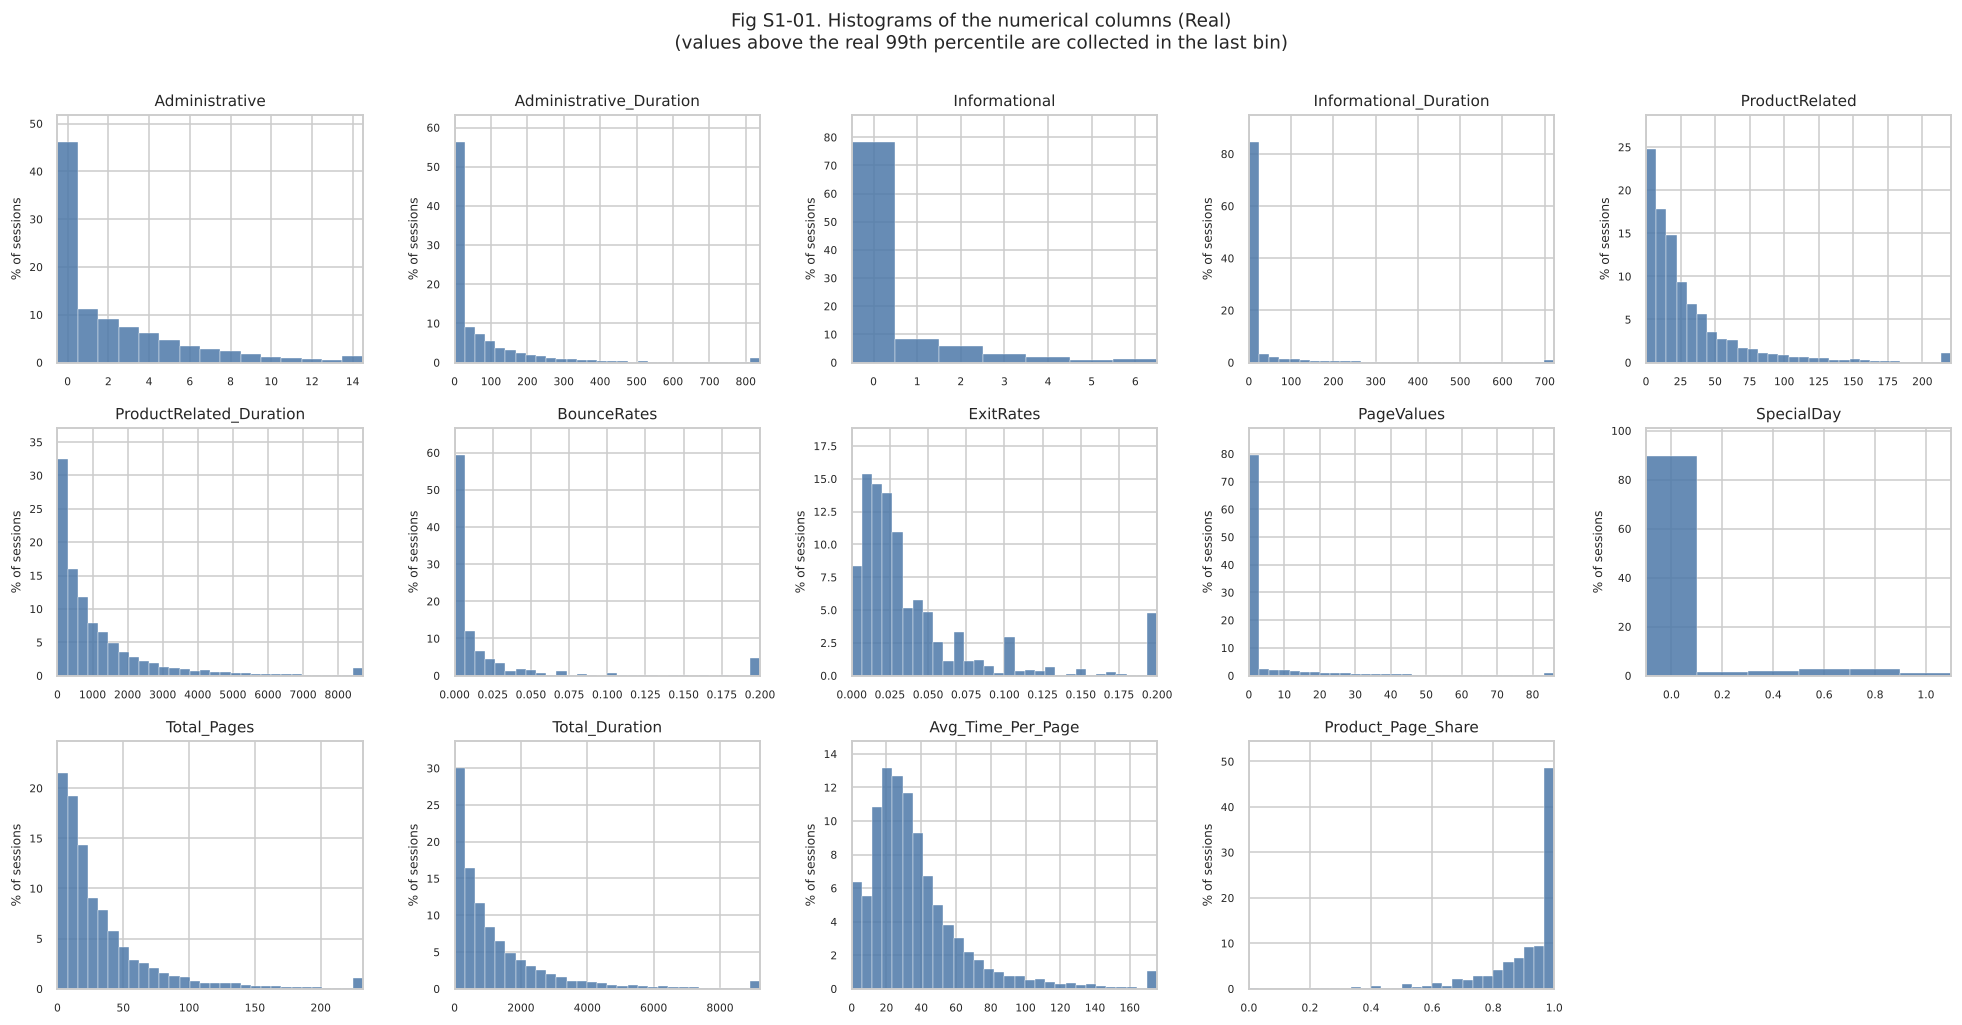

In [4]:
L.fig_histograms(df, S, COLOR, "Fig S1-01. Histograms of the numerical columns (Real)", FIG / "s1_01_histograms.png")

**Interpretation.** Every numerical column has a tall first bar and a long right tail. The three page counts and three durations decay smoothly from zero, BounceRates and ExitRates are concentrated near 0 with a small bump at the cap of 0.2, PageValues has a large spike at 0 and a flat low tail, and SpecialDay is 90% zero. Product_Page_Share is the only left-skewed column, piling up at 1.0 (sessions that visit only product pages). The last bin of each panel collects the roughly 1% of values above the real 99th percentile (the limits are saved in results/scenarios/plot_settings.json).

### 2.4 KDE plots

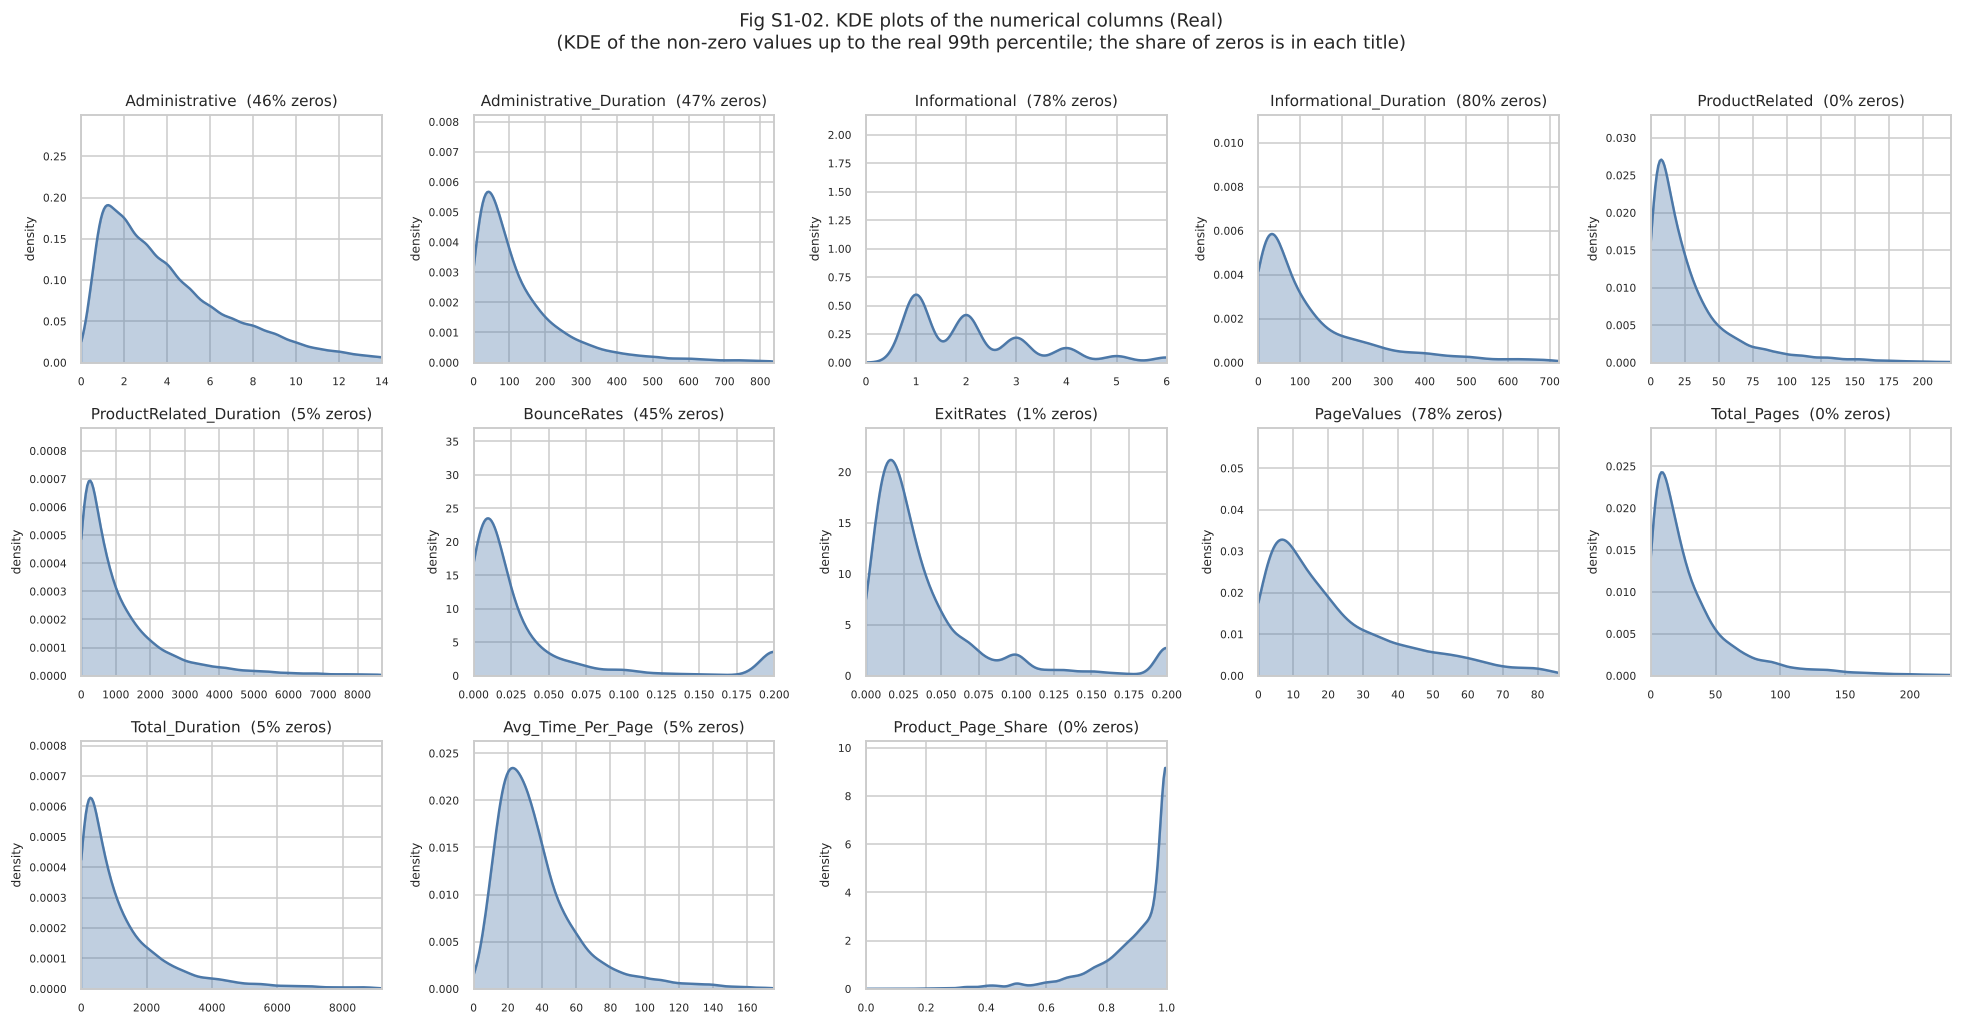

In [5]:
L.fig_kde(df, S, COLOR, "Fig S1-02. KDE plots of the numerical columns (Real)", FIG / "s1_02_kde.png")

**Interpretation.** With the zeros removed, the non-zero values of the duration and count columns follow a single skewed hump with a long tail, close to log-normal. Informational shows several peaks at 1, 2, 3 because it is a small integer count. ExitRates has its main peak at about 0.02 and smaller bumps at 0.1 and 0.2, which are values that many sessions share exactly (the 0.2 bump is the cap). The non-zero PageValues form a broad hump between about 5 and 60. Avg_Time_Per_Page peaks at about 25 seconds per page. Product_Page_Share rises steadily towards 1.0.

### 2.5 Box plots

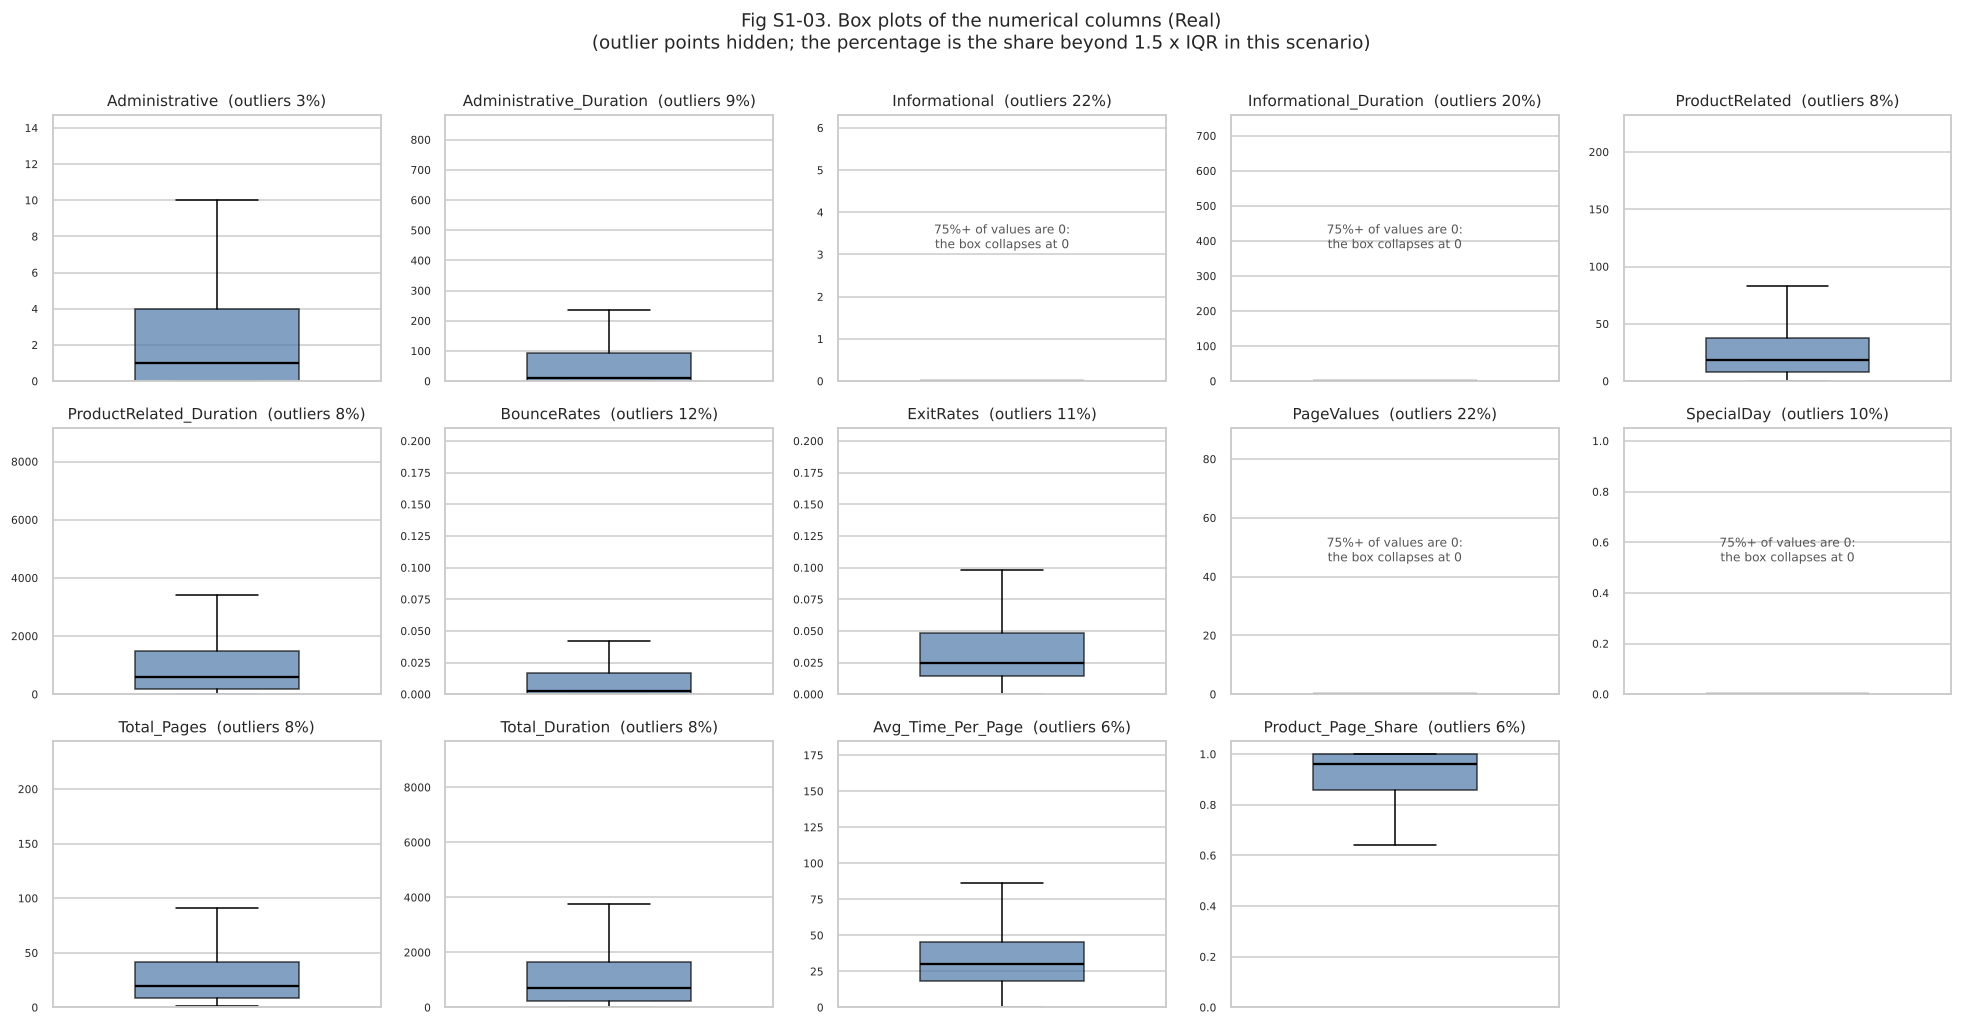

In [6]:
L.fig_boxplots(df, S, COLOR, "Fig S1-03. Box plots of the numerical columns (Real)", FIG / "s1_03_boxplots.png")

**Interpretation.** For the count and duration columns the middle half of sessions is narrow compared with the whisker length (for example ProductRelated: Q1 = 8, Q3 = 38, upper whisker about 85 pages), which confirms the long right tail. For Informational, Informational_Duration, PageValues and SpecialDay the box collapses at 0 because more than 75% of values are 0; the 20% to 22% outlier shares are the non-zero sessions. BounceRates and ExitRates have most values below 0.05 and 0.1 respectively. Product_Page_Share is the only column whose box sits close to the maximum (median 0.96).

### 2.6 Bar charts of the categorical columns

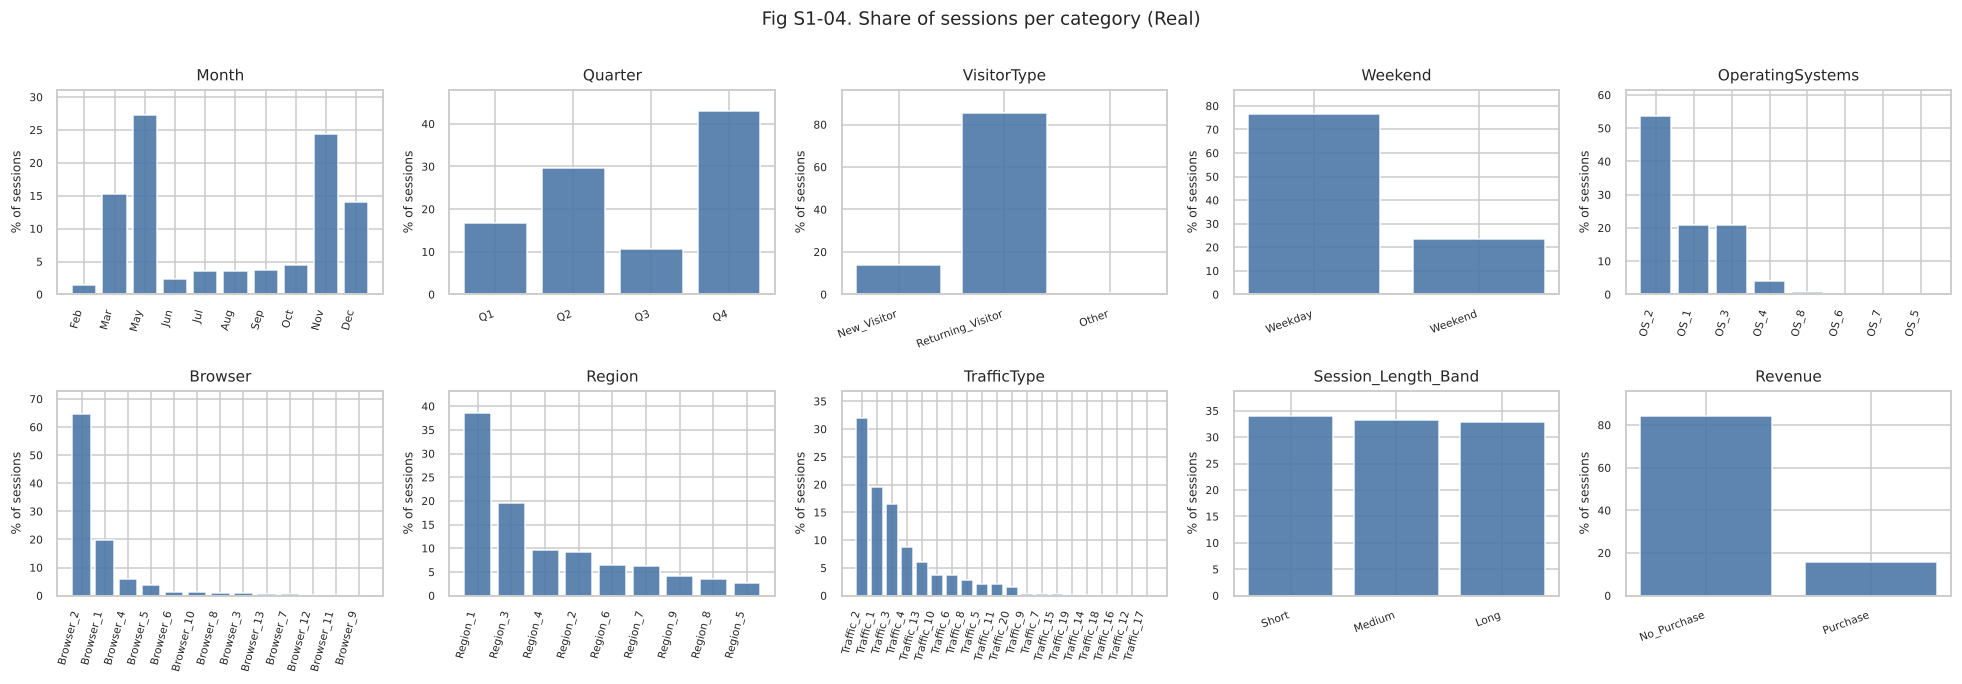

In [7]:
L.fig_categorical_bars(df, S, COLOR, "Fig S1-04. Share of sessions per category (Real)", FIG / "s1_04_categorical_bars.png")

**Interpretation.** The bar charts show how unevenly sessions are spread over categories: two months dominate (May and November), one operating system, one browser and one region account for roughly half or more of sessions, and traffic type 2 alone has 32%. Because the shares of the rare levels are tiny (about half of the operating-system, browser and traffic-type levels have under 1% of sessions each), comparisons of purchase rates for these levels would rest on very few sessions.

### 2.7 Donut charts

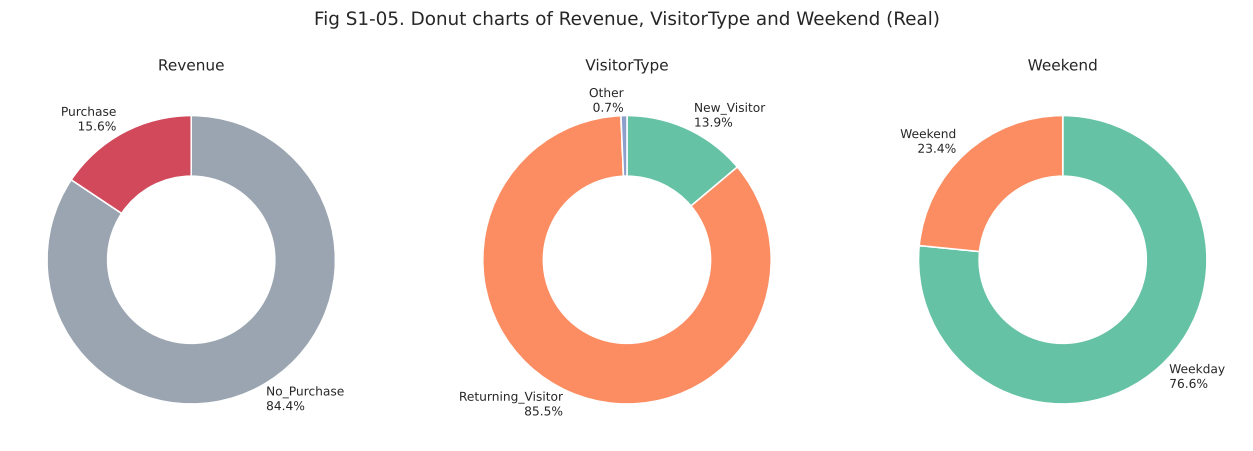

In [8]:
L.fig_donuts(df, S, "Fig S1-05. Donut charts of Revenue, VisitorType and Weekend (Real)", FIG / "s1_05_donuts.png")

**Interpretation.** The donuts give the shares at a glance: 84.4% of sessions end without a purchase and 15.6% with one, 85.5% of sessions come from returning visitors, and 76.6% happen on weekdays. The small 'Other' visitor type (0.7%) is too small for reliable conclusions.

## 3. Bivariate analysis
Four numerical pairs (scatter plots), four numerical-by-category comparisons (box plots), three purchase-rate comparisons (grouped bar charts) and the correlation heatmaps. The tests below give the statistical evidence for each pair.

In [9]:
tests = L.bivariate_tests(df)
tests.to_csv(RES / "bivariate_tests.csv", index=False)
tests.assign(**{"p-value": tests["p-value"].map(lambda p: "<0.0001" if p < 1e-4 else f"{p:.4f}")}).round({"effect": 3})

,test,pair,statistic,effect,p-value
0,correlation,ProductRelated ~ ProductRelated_Duration,Pearson r = 0.875; Spearman rho = 0.879,0.879,<0.0001
1,correlation,BounceRates ~ ExitRates,Pearson r = 0.902; Spearman rho = 0.589,0.589,<0.0001
2,correlation,ExitRates ~ PageValues,Pearson r = -0.174; Spearman rho = -0.304,-0.304,<0.0001
3,correlation,Total_Pages ~ PageValues,Pearson r = 0.067; Spearman rho = 0.348,0.348,<0.0001
4,Mann-Whitney U,PageValues by Revenue,"median purchase = 16.8, no purchase = 0",0.726,<0.0001
5,Mann-Whitney U,ExitRates by Revenue,"median purchase = 0.016, no purchase = 0.0283",-0.399,<0.0001
6,Mann-Whitney U,Total_Pages by Revenue,"median purchase = 32, no purchase = 19",0.318,<0.0001
7,Mann-Whitney U,Total_Duration by Revenue,"median purchase = 1.25e+03, no purchase = 601",0.344,<0.0001
8,chi-square,VisitorType x Revenue,"chi2 = 130.4, dof = 2",0.103,<0.0001
9,chi-square,Quarter x Revenue,"chi2 = 228.9, dof = 3",0.137,<0.0001


**Interpretation.** All four correlation pairs are statistically significant with very large samples, so effect size matters more than p-values. The strongest relationships are the product pages with product time (Spearman 0.88) and BounceRates with ExitRates (Pearson 0.90, but Spearman only 0.59, because many sessions sit at the same low values and a few at the cap). PageValues is moderately and negatively related to ExitRates (rho -0.30) and positively to Total_Pages (rho 0.35, while Pearson is only 0.07, which shows a monotonic but non-linear relation). Purchasing sessions differ strongly from non-purchasing ones on PageValues (rank-biserial 0.73), and moderately on ExitRates (-0.40), Total_Duration (0.34) and Total_Pages (0.32). Among the categorical variables, session length (Cramér's V 0.185), month (0.176), quarter (0.137) and visitor type (0.103) are related to purchase; Weekend is statistically significant (p = 0.0024) but tiny (V = 0.027).

### 3.1 Scatter plots (four pairs)

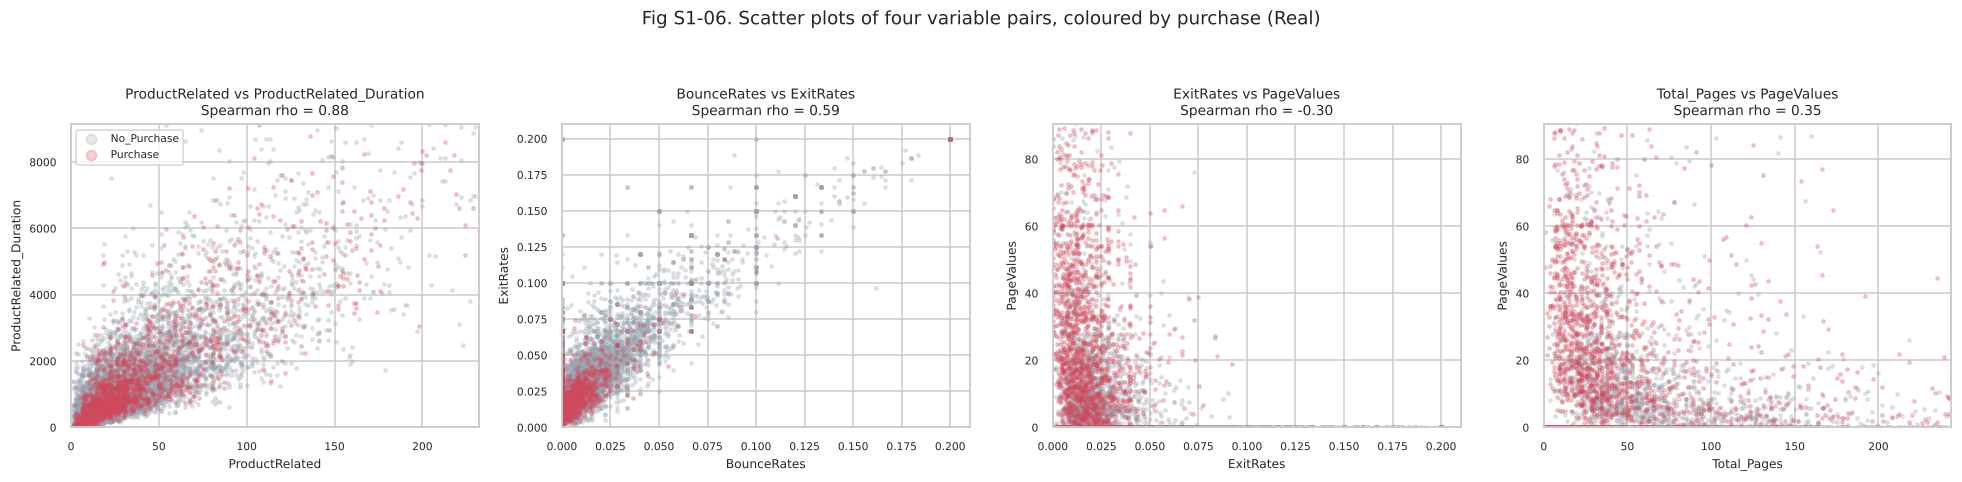

In [10]:
L.fig_scatter_pairs(df, S, "Fig S1-06. Scatter plots of four variable pairs, coloured by purchase (Real)", FIG / "s1_06_scatter_pairs.png")

**Interpretation.** Product pages and product time rise together along a clear diagonal band (rho 0.88); purchasing sessions (red) are spread along the whole band but concentrate in the upper right. Bounce and exit rates form a tight upward band that stops at the cap of 0.2. PageValues falls as ExitRates rises (rho -0.30): sessions with value are mostly below an exit rate of 0.05. PageValues grows with Total_Pages (rho 0.35), and most sessions with high PageValues are purchases (80% of the 578 sessions with PageValues above 40, against 15.6% overall).

### 3.2 Box plots across categories

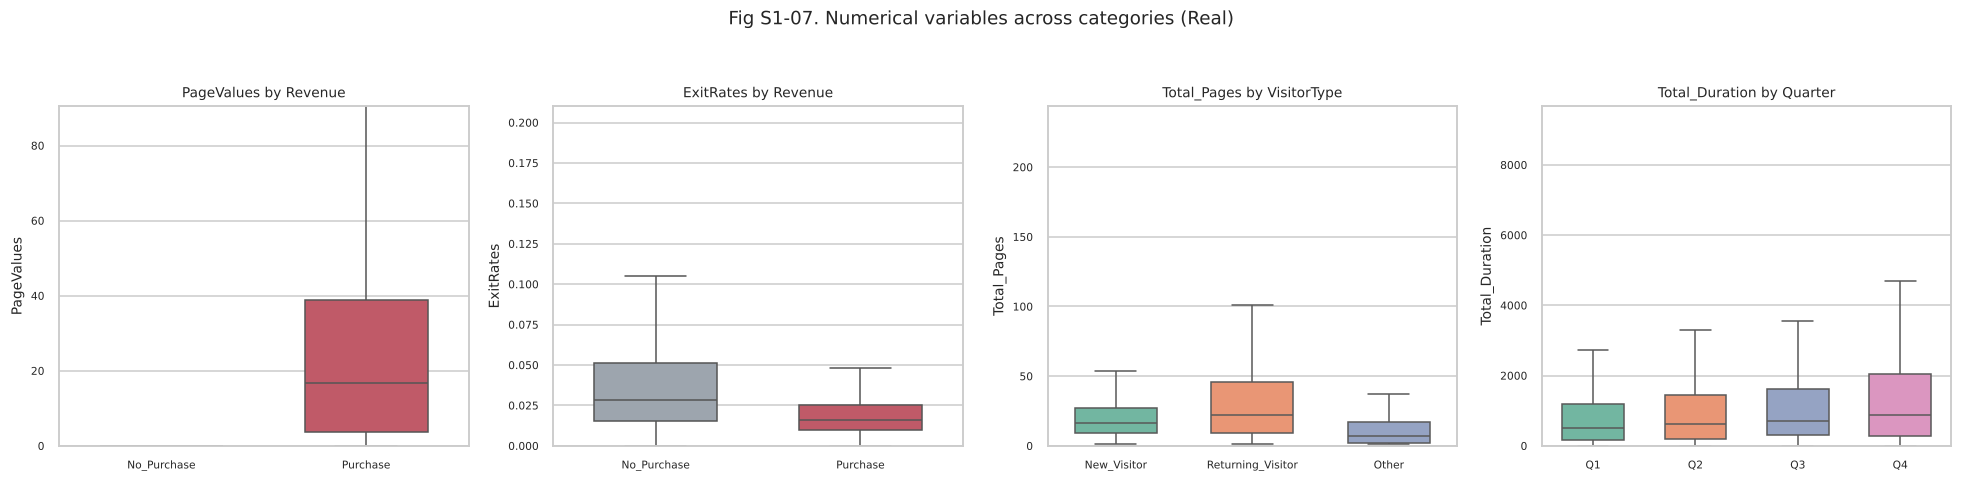

In [11]:
L.fig_box_by_category(df, S, "Fig S1-07. Numerical variables across categories (Real)", FIG / "s1_07_box_by_category.png")

**Interpretation.** PageValues separates the outcome sharply: the box of non-purchasing sessions sits at 0, while purchasing sessions have a median of 16.8 and a wide box. ExitRates is lower for purchasing sessions (median 0.016 against 0.028). Returning visitors view more pages than new visitors (the 'Other' group is smallest), and sessions in Q4 take longer in total than sessions in Q1 to Q3, which is consistent with Q4 having more purchases.

### 3.3 Grouped bar charts: purchase rate

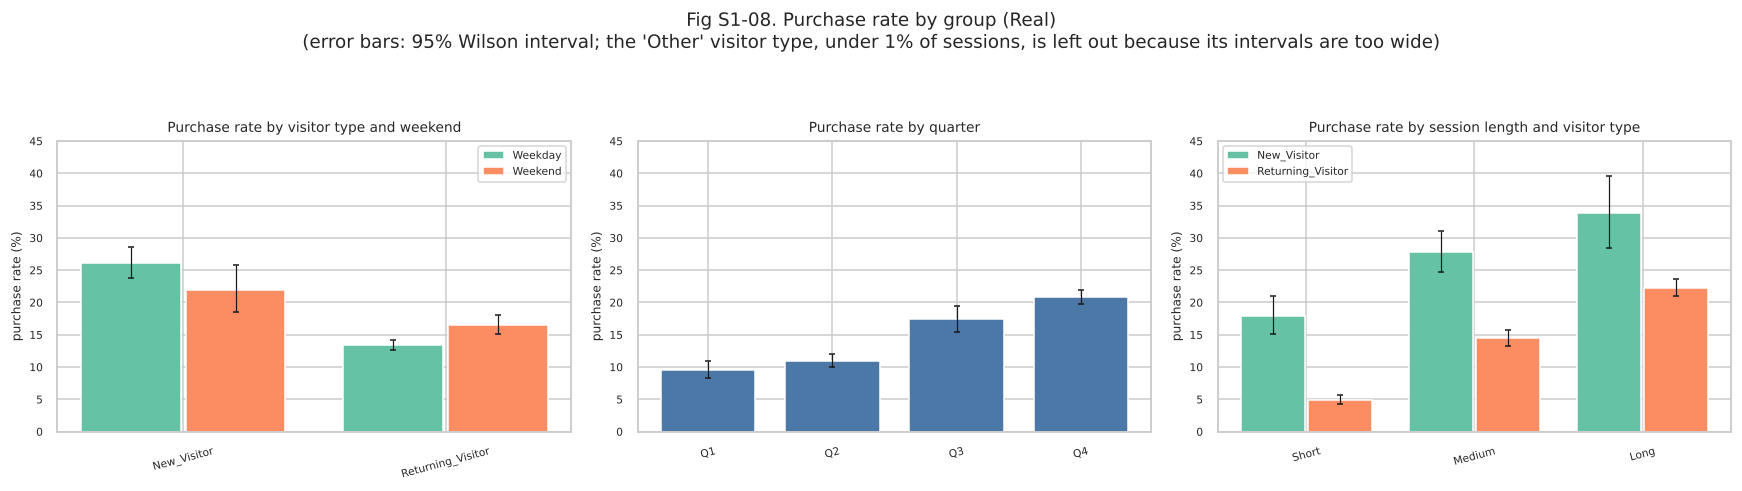

In [12]:
L.fig_purchase_rate_bars(df, S, "Fig S1-08. Purchase rate by group (Real)", FIG / "s1_08_purchase_rate_bars.png")

**Interpretation.** New visitors buy more often than returning ones (24.9% against 14.1% for weekdays and weekends combined; the intervals do not overlap), and on weekends returning visitors buy slightly more than on weekdays while new visitors buy less. The purchase rate grows with the quarter, from 9.6% in Q1 to 20.8% in Q4. It also grows steeply with session length: 7.0% for short, 17.1% for medium and 23.2% for long sessions, and the order holds for both visitor types. The 'Other' visitor type is left out because its intervals are too wide.

### 3.4 Correlation heatmaps

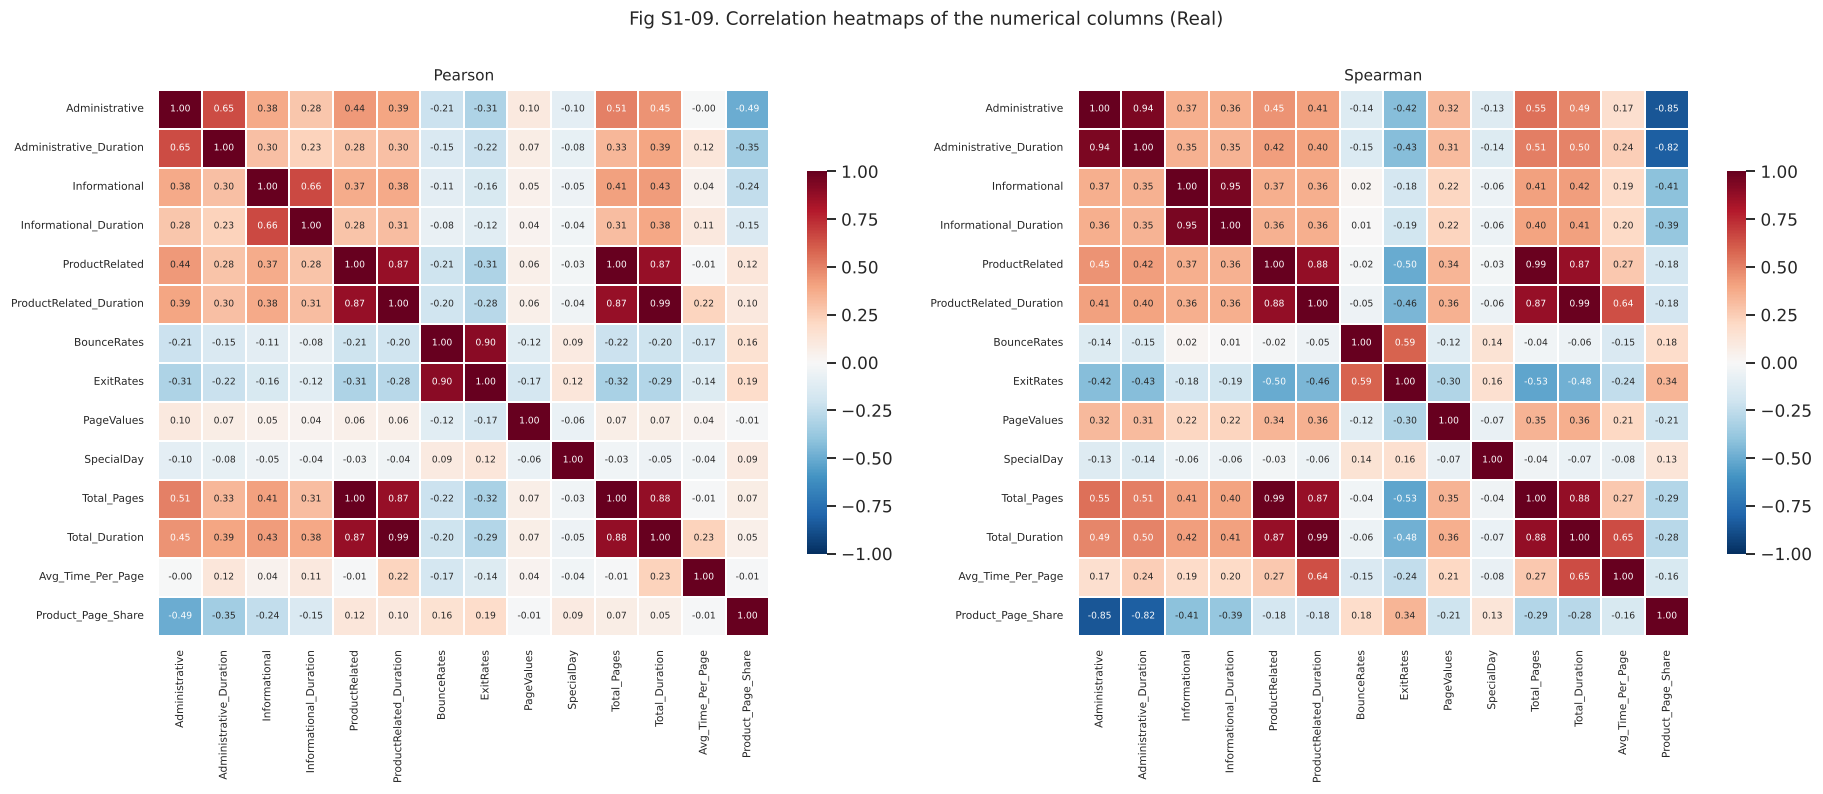

In [13]:
L.fig_correlation_heatmaps(df, "Fig S1-09. Correlation heatmaps of the numerical columns (Real)", FIG / "s1_09_correlation_heatmaps.png")
df[L.NUM].corr().to_csv(RES / "correlation_pearson.csv"); df[L.NUM].corr(method="spearman").to_csv(RES / "correlation_spearman.csv")

**Interpretation.** The strongest correlations are mechanical: Total_Pages is the sum of the three page counts (ProductRelated 1.00), and Total_Duration follows ProductRelated_Duration (0.99). Beyond those, BounceRates and ExitRates (0.90), the product count and time (0.87), and each page type with its duration (Administrative 0.65, Informational 0.66) are strongly related. Product_Page_Share is negatively related to Administrative (-0.49) and Administrative_Duration (-0.35). PageValues has weak Pearson correlations with everything (the largest is -0.17 with ExitRates), but the Spearman heatmap shows more: rho -0.30 with ExitRates and 0.35 with Total_Pages. The Pearson and Spearman heatmaps differ most for the zero-inflated columns.

## 4. Multivariate analysis
Three patterns are examined: (1) the relation between value, exit behaviour, size of the visit and time per page for buying and non-buying sessions; (2) month x visitor-type groups (activity against purchase rate); (3) PageValues against ExitRates within each visitor type, plus the purchase rate by quarter and visitor type.

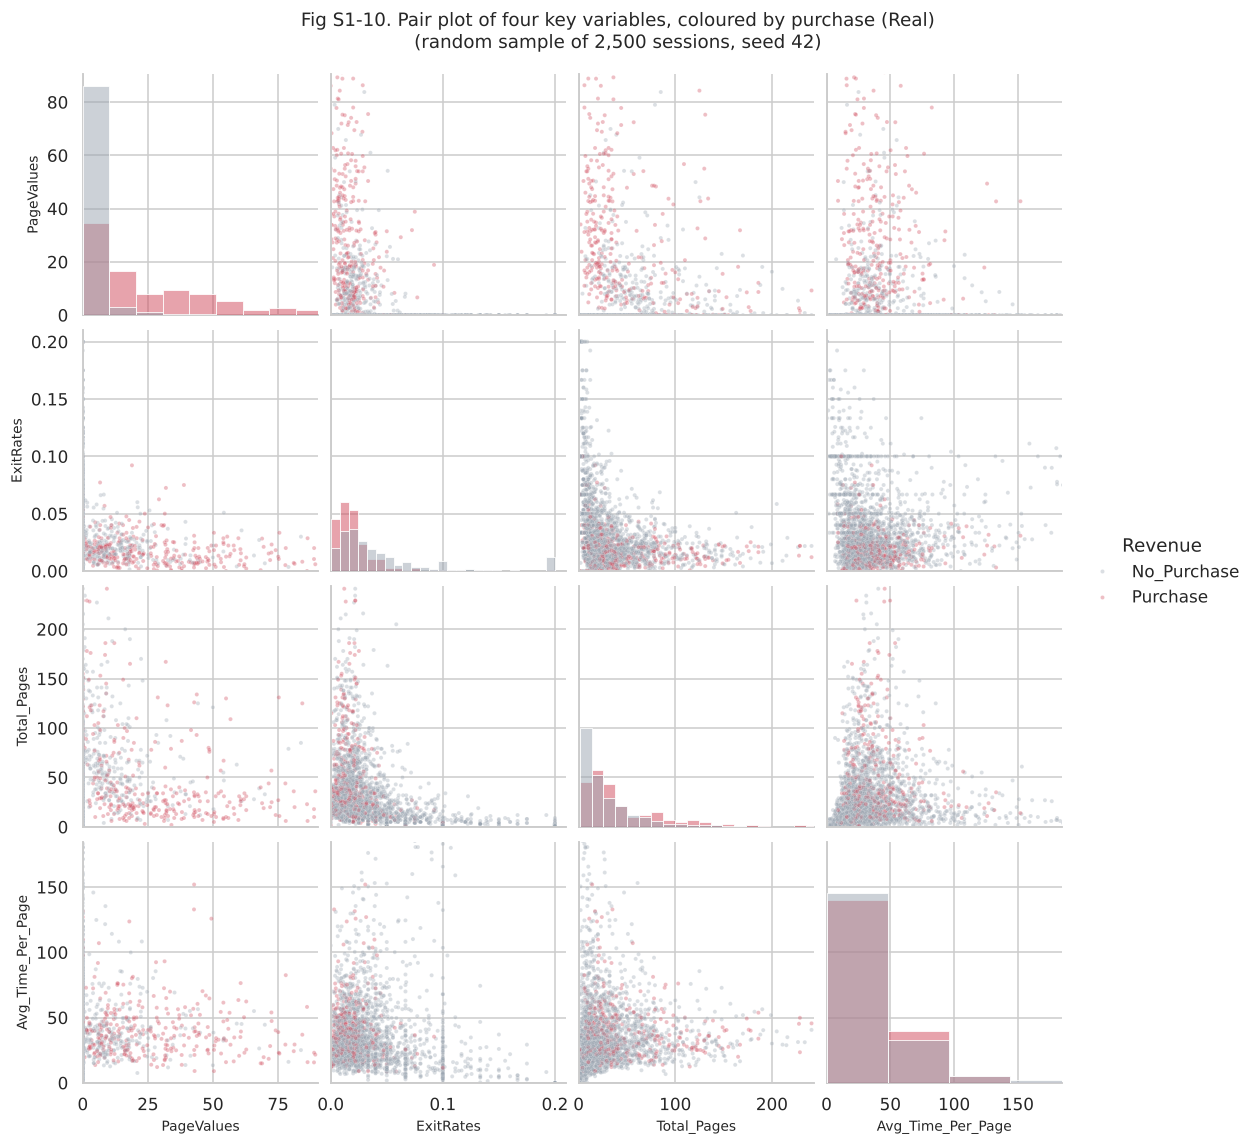

In [14]:
L.fig_pairplot(df, S, "Fig S1-10. Pair plot of four key variables, coloured by purchase (Real)", FIG / "s1_10_pairplot.png")

**Interpretation.** In the pair plot, purchasing sessions occupy the upper part of PageValues and the lower part of ExitRates; about 80% of sessions with PageValues above 40 are purchases (against 15.6% overall). Total_Pages and Avg_Time_Per_Page overlap heavily between the two outcomes, so they separate them less clearly. The histograms on the diagonal confirm that buyers have a much wider PageValues distribution. Sessions with an exit rate above 0.1 are almost never purchases (0.6% of 981 sessions).

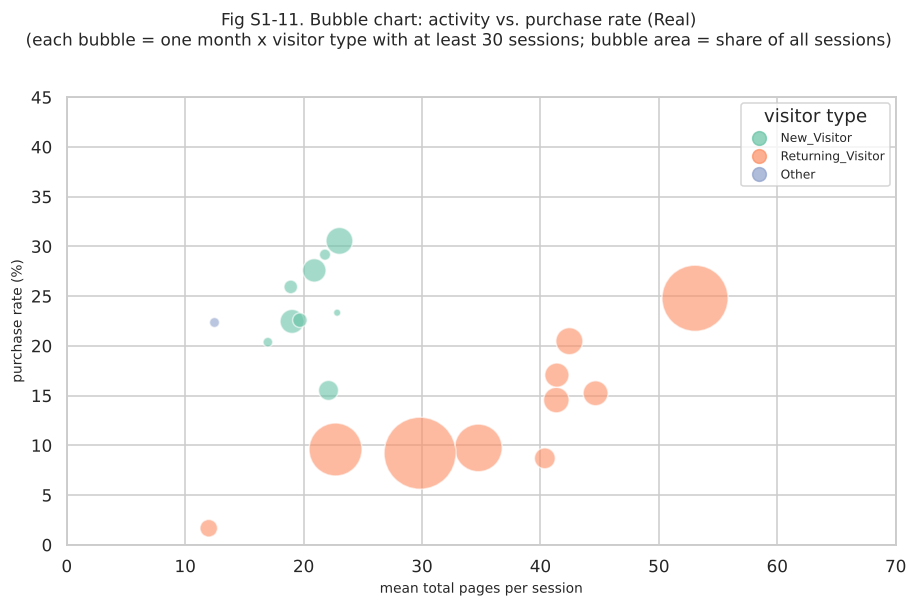

In [15]:
L.fig_bubble(df, S, "Fig S1-11. Bubble chart: activity vs. purchase rate (Real)", FIG / "s1_11_bubble.png")
L.bubble_table(df).to_csv(RES / "bubble_table.csv", index=False)

**Interpretation.** Each bubble is a month and visitor-type group. Purchase rate and activity differ strongly between groups: the largest returning-visitor groups in May, March and December have a purchase rate of about 9% to 10% with 23 to 35 mean pages, while returning visitors in November reach 24.8% with 53 mean pages, and October 20.5% with 42 pages. New visitors in November convert at 30.5% with only 23 pages. So in the real data a higher purchase rate often goes with more pages, but not always: new visitors buy with fewer pages. The purchase rate of the groups ranges from 1.7% to 30.5%.

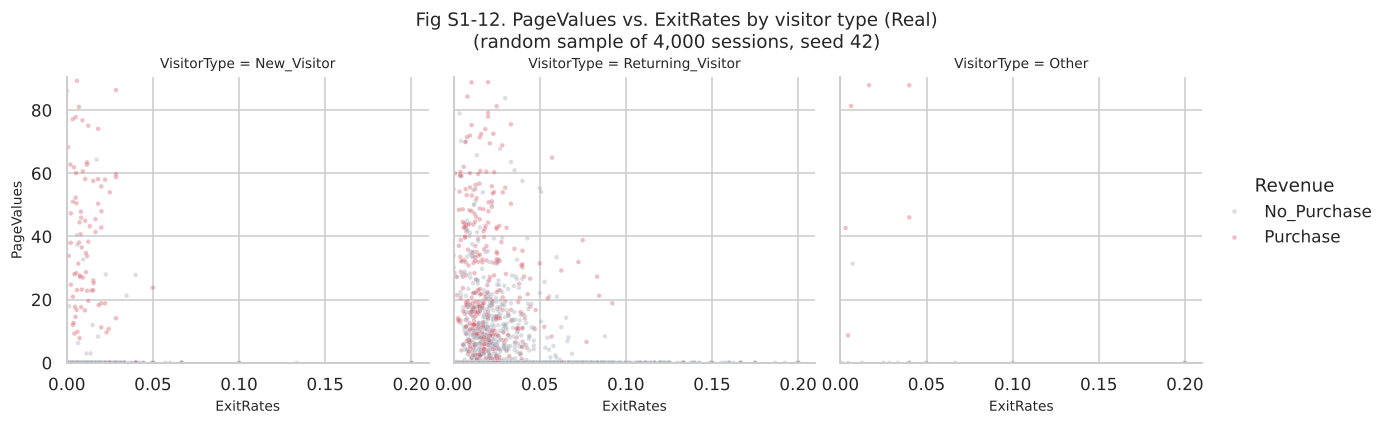

In [16]:
L.fig_facets(df, S, "Fig S1-12. PageValues vs. ExitRates by visitor type (Real)", FIG / "s1_12_facets.png")

**Interpretation.** The relation of PageValues to ExitRates holds within each visitor type: Spearman rho is -0.22 for new visitors, -0.32 for returning visitors and -0.47 for the very small 'Other' group (81 sessions). Purchasing sessions (red) are found at higher PageValues in every panel. New visitors have lower exit rates than returning visitors (median 0.013 against 0.028; 92% against 73% of sessions are below 0.05).

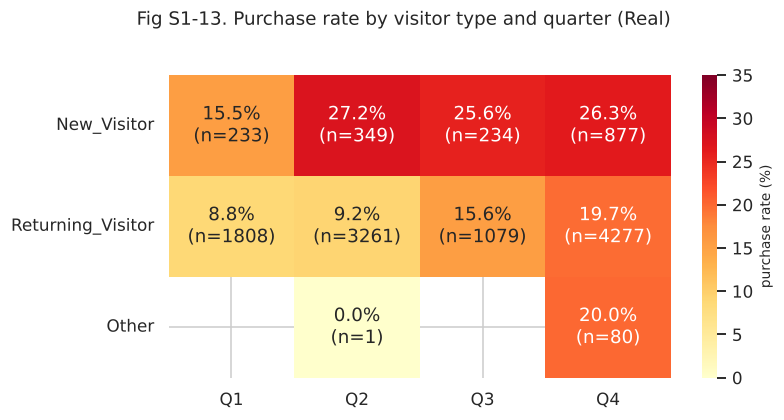

,pattern,group,value,n
0,ExitRates ~ PageValues within visitor type (Sp...,New_Visitor,-0.225,1693
1,ExitRates ~ PageValues within visitor type (Sp...,Other,-0.467,81
2,ExitRates ~ PageValues within visitor type (Sp...,Returning_Visitor,-0.323,10425
3,Total_Pages ~ PageValues within outcome (Spear...,No_Purchase,0.367,10291
4,Total_Pages ~ PageValues within outcome (Spear...,Purchase,-0.224,1908
5,Purchase-rate gap New minus Returning visitors...,Q1,6.656,2041
6,Purchase-rate gap New minus Returning visitors...,Q2,18.052,3611
7,Purchase-rate gap New minus Returning visitors...,Q3,10.071,1313
8,Purchase-rate gap New minus Returning visitors...,Q4,6.606,5234


In [17]:
L.fig_rate_matrix(df, S, "Fig S1-13. Purchase rate by visitor type and quarter (Real)", FIG / "s1_13_rate_matrix.png")
mv = L.multivariate_evidence(df); mv.to_csv(RES / "multivariate_evidence.csv", index=False)
mv.round(3)

**Interpretation.** Purchase rate depends on both visitor type and quarter. Returning visitors rise from 8.8% in Q1 to 19.7% in Q4. New visitors buy at 25.6% to 27.2% in Q2 to Q4 but only 15.5% in Q1. The advantage of new visitors over returning visitors is not constant: 6.7 percentage points in Q1, 18.1 in Q2, 10.1 in Q3 and 6.6 in Q4. 'Other' visitors only occur in Q2 (1 session) and Q4 (80 sessions). The Spearman correlation of ExitRates and PageValues is the same sign in all visitor types, and the correlation of Total_Pages with PageValues changes sign between non-purchasing (+0.37) and purchasing (-0.22) sessions: among buyers, more pages do not mean a higher page value.

## 5. Trends
The data has a `Month` label but no date column (no day and no year), so daily and yearly trends are not possible. Monthly trends and seasonality are analysed for the ten months present; the four quarters are used as a coarser view.

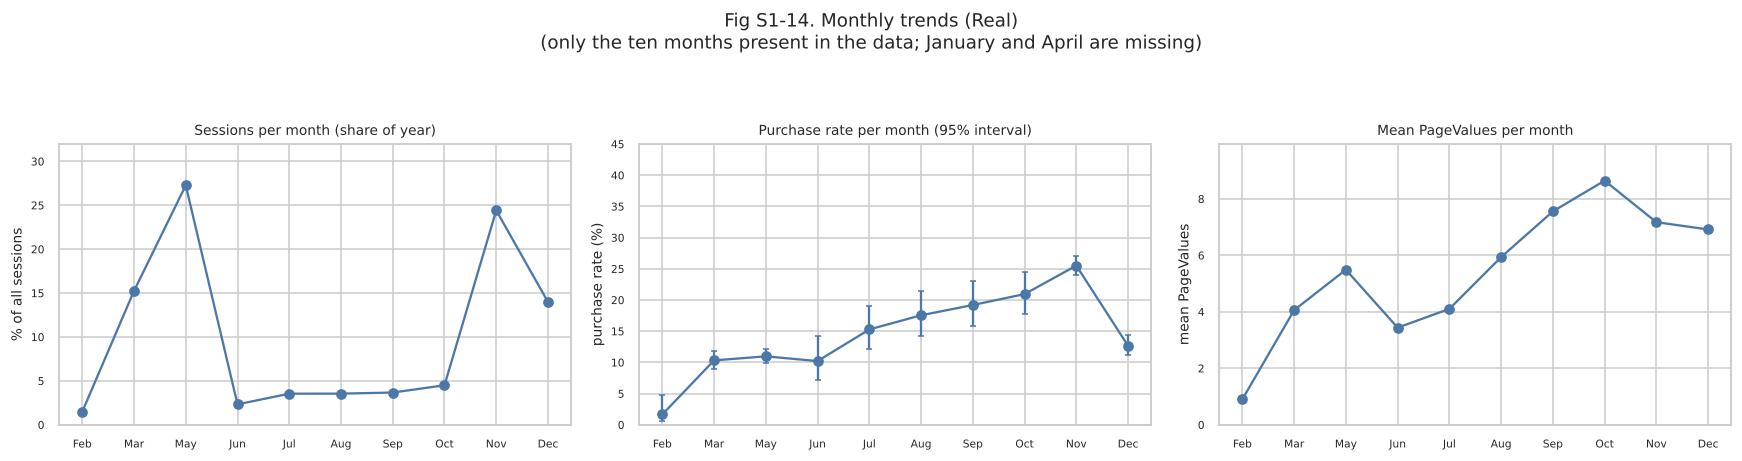

,n,purchases,rate,lo,hi,share,mean_PageValues
Month,,,,,,,
Feb,181,3,1.66,0.57,4.76,1.48,0.91
Mar,1860,192,10.32,9.02,11.79,15.25,4.06
May,3327,365,10.97,9.95,12.08,27.27,5.49
Jun,284,29,10.21,7.20,14.28,2.33,3.44
Jul,432,66,15.28,12.19,18.98,3.54,4.10
Aug,433,76,17.55,14.26,21.42,3.55,5.94
Sep,448,86,19.20,15.82,23.10,3.67,7.56
Oct,549,115,20.95,17.75,24.55,4.50,8.65
Nov,2979,760,25.51,23.98,27.11,24.42,7.17


In [18]:
L.fig_monthly(df, S, COLOR, "Fig S1-14. Monthly trends (Real)", FIG / "s1_14_monthly_trend.png", LIM)
mt = L.monthly_table(df); mt.to_csv(RES / "monthly_table.csv")
mt.round(2)

**Interpretation.** Traffic is highly seasonal: May and November together bring 52% of sessions, with March and December adding another 29%, while February and June to October have 1.5% to 4.5% each. Conversion follows a different pattern: it is lowest in February (1.7%, 181 sessions), about 10% to 11% in March, May and June, rises to 15.3% in July, 17.6% in August, 19.2% in September and 20.9% in October, peaks in November at 25.5% (95% interval 24.0% to 27.1%) and falls back to 12.7% in December. Mean PageValues follows a similar rise from 0.9 in February to 8.65 in October. So May has a lot of traffic but a low purchase rate, and November has both. A chi-square test of month against purchase gives Cramér's V of 0.176 (p < 0.0001). There is only one year of data and no year column, so we cannot tell whether this is a yearly pattern or one year's special events.

## 6. Key findings

In [19]:
# numbers quoted in the findings, computed from the saved tables
ev = {}
ev["purchase_rate"] = 100 * (df.Revenue == "Purchase").mean()
ev["visitor_rate"] = L.rate_table(df, "VisitorType").set_index("VisitorType")[["n", "rate", "lo", "hi"]].round(2)
ev["quarter_rate"] = L.rate_table(df, "Quarter").set_index("Quarter")[["n", "rate", "lo", "hi"]].round(2)
ev["top_corr"] = (df[L.NUM].corr().where(np.triu(np.ones((len(L.NUM), len(L.NUM))), 1).astype(bool)).stack().rename("r").reset_index()
                  .assign(abs_r=lambda d: d.r.abs()).sort_values("abs_r", ascending=False).head(6).round(3))
for k, v in ev.items():
    print("==", k); print(v if not isinstance(v, float) else round(v, 2))

== purchase_rate
15.64
== visitor_rate
                       n   rate     lo     hi
VisitorType                                  
New_Visitor         1693  24.93  22.92  27.04
Other                 81  19.75  12.54  29.70
Returning_Visitor  10425  14.10  13.45  14.78
== quarter_rate
            n   rate     lo     hi
Quarter                           
Q1       2041   9.55   8.35  10.91
Q2       3611  10.91   9.94  11.97
Q3       1313  17.36  15.41  19.51
Q4       5234  20.84  19.77  21.97
== top_corr
                    level_0                  level_1      r  abs_r
51           ProductRelated              Total_Pages  0.997  0.997
60  ProductRelated_Duration           Total_Duration  0.993  0.993
63              BounceRates                ExitRates  0.902  0.902
85              Total_Pages           Total_Duration  0.876  0.876
46           ProductRelated  ProductRelated_Duration  0.875  0.875
59  ProductRelated_Duration              Total_Pages  0.874  0.874


### Summary of the key findings


**Finding 1: Value pages are the clearest signal of purchase intent, and purchases are a minority.**
*Observation:* only 15.64% of sessions end in a purchase (95% interval about 15.0% to 16.3%), and 78% of sessions have PageValues of 0. *Statistical evidence:* the median PageValues is 16.8 for purchasing sessions and 0 for non-purchasing ones; Mann-Whitney rank-biserial correlation 0.73 (p < 0.0001), the largest effect of any numerical variable. *Figures:* S1-05, S1-07. *Significance:* PageValues is the strongest predictor of purchase in this data, and the class imbalance (about 1 in 6.4) means that any model or comparison must look at the purchase rate, not just accuracy.

**Finding 2: Conversion is strongly seasonal and does not follow traffic.**
*Observation:* November converts at 25.5% (24.0% to 27.1%) while May, with a similar volume, converts at 11.0% (10.0% to 12.1%); February converts at 1.7%. *Statistical evidence:* chi-square of Month against Revenue gives Cramér's V 0.176 (p < 0.0001); quarter gives 0.137, with 20.8% in Q4 against 9.6% in Q1. *Figures:* S1-14, S1-08. *Significance:* marketing or traffic volume alone does not explain purchases; promotions or season effects probably matter, so month must be controlled for in any analysis.

**Finding 3: New visitors convert more often than returning visitors, but most purchases still come from returning visitors.**
*Observation:* 24.9% of new-visitor sessions end in a purchase against 14.1% of returning-visitor sessions. *Statistical evidence:* the intervals (22.9% to 27.0% against 13.4% to 14.8%) do not overlap; chi-square Cramér's V 0.103 (p < 0.0001). New visitors are only 13.9% of sessions, so returning visitors still account for 1,470 of the 1,908 purchases. *Figures:* S1-08, S1-13. *Significance:* the gap changes with the season (18.1 percentage points in Q2, 6.6 in Q4), so the effect of visitor type depends on the quarter.

**Finding 4: Longer, deeper sessions convert much more.**
*Observation:* purchase rate is 7.0% for short, 17.1% for medium and 23.2% for long sessions. *Statistical evidence:* Cramér's V 0.185 (the largest of the categorical variables); purchasing sessions have a median of 32 pages against 19 and 1,250 s against 601 s (rank-biserial 0.32 and 0.34). Product pages and product time are closely linked (Spearman 0.88). *Figures:* S1-06, S1-08. *Significance:* engagement is a reliable signal, but session length is derived from the page counts, so it is not independent of them.

**Finding 5: Exit behaviour separates buyers from non-buyers.**
*Observation:* purchasing sessions have lower exit rates (median 0.016 against 0.028). *Statistical evidence:* rank-biserial -0.40 (p < 0.0001); BounceRates and ExitRates correlate at Pearson 0.90 (Spearman 0.59), and ExitRates is negatively related to PageValues (rho -0.30, still negative within each visitor type). *Figures:* S1-06, S1-07, S1-12. *Significance:* bounce and exit rates carry almost the same information, so they should not both be used as independent predictors.

**Finding 6: The numerical columns are zero-inflated and heavily skewed, so means and the IQR rule mislead.**
*Observation:* 78% to 80% of sessions have zero PageValues or informational time; skewness is between 2 and 10. *Statistical evidence:* the IQR rule flags 22% of PageValues values, only because Q3 = 0; the mean ProductRelated of 31.6 is nearly twice the median of 18. *Figures:* S1-01, S1-02, S1-03. *Significance:* medians, rank-based tests and effect sizes are the appropriate tools, and a generator that cannot reproduce the zero spike and the tail will look different on these columns.

## 7. Outputs
Figures: `figures/real/scenario1/`; tables: `results/scenarios/scenario1_real/`.